# 1. Імпорт бібліотек та конфігурація параметрів моделювання

In [1]:
#%pip install numpy scipy torch matplotlib plotly

In [2]:
import heapq
import time
from dataclasses import dataclass
from typing import Dict, List, Tuple

import matplotlib.pyplot as plt
import numpy as np
import plotly.graph_objects as go
import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy.ndimage import gaussian_filter
from scipy.sparse.csgraph import connected_components
from scipy.special import erf

# Фіксація генераторів випадкових чисел для відтворюваності експерименту
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Обчислювальний пристрій: {DEVICE}")


@dataclass
class SimConfig:
    # Параметри тривимірного простору Omega (метри)
    x_max: float = 400.0
    y_max: float = 400.0
    z_max: float = 120.0
    voxel_size: float = 10.0  # Сітка 40 x 40 x 12 вокселів

    # Параметри рою та кінематики вузлів
    n_drones: int = 6
    dt: float = 0.5
    n_steps: int = 240
    v_max: float = 12.0
    a_max: float = 6.0
    wind_sigma: float = 0.25

    # Стартова та цільова області
    start_center: Tuple[float, float, float] = (40.0, 40.0, 35.0)
    goal_point: Tuple[float, float, float] = (355.0, 355.0, 55.0)
    goal_radius: float = 22.0

    # Енергетична модель вузла (умовні Вт та Вт*год)
    energy_init: float = 120.0
    p_hover: float = 110.0
    alpha_v: float = 0.35
    alpha_u: float = 0.50
    p_comp: float = 4.0
    p_comm: float = 2.5

    # Радіоканал та mesh-мережа
    p_tx: float = 1.0
    g_0: float = 8000.0
    gamma_path: float = 2.0
    mu_obs: float = 0.08
    n_0: float = 1.0
    i_crit: float = 5.2
    sinr_min: float = 0.8
    sinr_beta: float = 4.0
    bandwidth_hz: float = 1e6
    packet_bits: float = 256.0
    slot_dt: float = 0.02

    # Кооперативне позиціонування
    odo_drift_base: float = 0.28
    range_noise_base: float = 0.6

    # Параметри локального ройового контролера
    k_goal: float = 2.6
    k_obs: float = 95.0
    k_sep: float = 55.0
    k_coh: float = 1.6
    k_align: float = 0.45
    k_jam_loc: float = 3.2
    r_sense: float = 28.0
    d_min_sep: float = 13.0
    d_opt_mesh: float = 34.0
    r_max_mesh: float = 95.0
    tau_pred: float = 1.8

    # Глобальний обчислювач (розташування базової станції та параметри A*)
    base_station: Tuple[float, float, float] = (25.0, 25.0, 75.0)
    uplink_sinr_min: float = 0.35
    uplink_g0: float = 85000.0
    global_update_period: int = 10
    mc_samples: int = 12
    lam_dist: float = 1.0
    lam_jam: float = 45.0
    lam_obs: float = 200.0
    lam_ent: float = 8.0


CFG = SimConfig()

Обчислювальний пристрій: cuda


# 2. Математична модель тривимірного простору (перешкоди, трасування, поле завад)

In [3]:
class Environment3D:
    def __init__(
        self,
        cfg: SimConfig,
        obstacles: List[Tuple[float, float, float, float, float, float]],
        jammers: List[Dict],
    ):
        self.cfg = cfg
        self.obstacles = np.array(obstacles, dtype=np.float32)  # (K, 6)
        self.jammers = jammers

        self.nx = int(round(cfg.x_max / cfg.voxel_size))
        self.ny = int(round(cfg.y_max / cfg.voxel_size))
        self.nz = int(round(cfg.z_max / cfg.voxel_size))

        xs = (np.arange(self.nx) + 0.5) * cfg.voxel_size
        ys = (np.arange(self.ny) + 0.5) * cfg.voxel_size
        zs = (np.arange(self.nz) + 0.5) * cfg.voxel_size
        self.grid_x, self.grid_y, self.grid_z = np.meshgrid(xs, ys, zs, indexing="ij")
        self.grid_points = np.stack([self.grid_x, self.grid_y, self.grid_z], axis=-1)  # (Nx, Ny, Nz, 3)

        # Істинна зайнятість та поле знакової відстані (SDF)
        self.sdf_grid = self.compute_sdf(self.grid_points.reshape(-1, 3)).reshape(self.nx, self.ny, self.nz)
        self.occ_grid = (self.sdf_grid <= 0.0).astype(np.float32)
        self.sdf_grad_grid = np.stack(np.gradient(self.sdf_grid, cfg.voxel_size), axis=-1)

        # Істинне поле завад на воксельній сітці
        flat_pts = self.grid_points.reshape(-1, 3)
        self.true_jam_grid = self.true_interference(flat_pts).reshape(self.nx, self.ny, self.nz)

    def compute_sdf(self, points: np.ndarray) -> np.ndarray:
        """Обчислення точної знакової відстані d_O(r) до найближчої прямокутної перешкоди."""
        pts = np.atleast_2d(points)
        min_sdf = np.full(pts.shape[0], np.inf, dtype=np.float32)
        for box in self.obstacles:
            b_min = box[:3]
            b_max = box[3:]
            center = 0.5 * (b_min + b_max)
            half = 0.5 * (b_max - b_min)
            q = np.abs(pts - center) - half
            outside = np.linalg.norm(np.maximum(q, 0.0), axis=1)
            inside = np.minimum(np.max(q, axis=1), 0.0)
            sdf = outside + inside
            min_sdf = np.minimum(min_sdf, sdf)
        return min_sdf

    def sample_sdf_and_normal(self, points: np.ndarray) -> Tuple[np.ndarray, np.ndarray]:
        """Оцінювання SDF та одиничної зовнішньої нормалі в довільних точках."""
        pts = np.atleast_2d(points)
        sdf = self.compute_sdf(pts)
        eps = 0.5
        normals = np.zeros_like(pts)
        for ax in range(3):
            delta = np.zeros(3, dtype=np.float32)
            delta[ax] = eps
            normals[:, ax] = (self.compute_sdf(pts + delta) - self.compute_sdf(pts - delta)) / (2.0 * eps)
        norms = np.linalg.norm(normals, axis=1, keepdims=True) + 1e-6
        return sdf, normals / norms

    def ray_attenuation(self, pts_a: np.ndarray, pts_b: np.ndarray, n_samples: int = 16) -> np.ndarray:
        """Коефіцієнт прозорості середовища A_пер(r_a, r_b) через променеве трасування."""
        # pts_a: (M, 3), pts_b: (M, 3) або трансльовані масиви
        s = np.linspace(0.0, 1.0, n_samples, dtype=np.float32)[:, None, None]  # (S, 1, 1)
        a = np.atleast_2d(pts_a)[None, :, :]
        b = np.atleast_2d(pts_b)[None, :, :]
        seg_len = np.linalg.norm(b - a, axis=-1)[0]  # (M,)
        rays = (a + s * (b - a)).reshape(-1, 3)
        occ = (self.compute_sdf(rays) <= 0.0).reshape(n_samples, -1)
        optical_depth = occ.mean(axis=0) * seg_len
        return np.exp(-self.cfg.mu_obs * optical_depth)

    def true_interference(self, points: np.ndarray) -> np.ndarray:
        """Істинна інтенсивність поля радіоелектронних завад I(r)."""
        pts = np.atleast_2d(points)
        total = np.full(pts.shape[0], self.cfg.n_0, dtype=np.float32)
        for jm in self.jammers:
            src = np.asarray(jm["pos"], dtype=np.float32)[None, :]
            diff = pts - src
            dist = np.linalg.norm(diff, axis=1)
            gamma = jm.get("gamma", 1.85)
            # Діаграма спрямованості (ізотропна або зі слабкою направленістю)
            if "dir" in jm:
                dir_vec = np.asarray(jm["dir"], dtype=np.float32)
                dir_vec = dir_vec / (np.linalg.norm(dir_vec) + 1e-6)
                cos_ang = np.clip(np.sum((diff / (dist[:, None] + 1e-6)) * dir_vec[None, :], axis=1), -1.0, 1.0)
                gain = 0.55 + 0.9 * (0.5 * (1.0 + cos_ang)) ** 2
            else:
                gain = 1.0
            src_rep = np.repeat(src, pts.shape[0], axis=0)
            atten = self.ray_attenuation(pts, src_rep, n_samples=14)
            total += (jm["power"] * gain * atten) / (np.power(dist, gamma) + 25.0)
        return total

    def point_to_voxel(self, points: np.ndarray) -> np.ndarray:
        pts = np.atleast_2d(points)
        idx = np.floor(pts / self.cfg.voxel_size).astype(int)
        idx[:, 0] = np.clip(idx[:, 0], 0, self.nx - 1)
        idx[:, 1] = np.clip(idx[:, 1], 0, self.ny - 1)
        idx[:, 2] = np.clip(idx[:, 2], 0, self.nz - 1)
        return idx


# Ініціалізація цільового сценарію середовища
OBSTACLES = [
    (110.0, 70.0, 0.0, 160.0, 195.0, 85.0),
    (185.0, 175.0, 0.0, 245.0, 255.0, 95.0),
    (95.0, 245.0, 0.0, 155.0, 325.0, 75.0),
    (265.0, 90.0, 0.0, 330.0, 170.0, 90.0),
    (260.0, 270.0, 0.0, 310.0, 330.0, 70.0),
]

JAMMERS = [
    {"pos": (175.0, 150.0, 42.0), "power": 5800.0, "gamma": 1.85},
    {"pos": (255.0, 245.0, 48.0), "power": 7200.0, "gamma": 1.85, "dir": (-0.6, -0.7, 0.1)},
    {"pos": (140.0, 305.0, 38.0), "power": 4400.0, "gamma": 1.90},
]

env = Environment3D(CFG, OBSTACLES, JAMMERS)
print(
    f"Простір ініціалізовано: сітка {env.nx}x{env.ny}x{env.nz}, "
    f"мін./макс. завади: {env.true_jam_grid.min():.2f} / {env.true_jam_grid.max():.2f}"
)

Простір ініціалізовано: сітка 40x40x12, мін./макс. завади: 1.00 / 161.91


# 3. Модель радіоканалу mesh-мережі, зв’язності та окремого вузла

In [4]:
def compute_mesh_links(
    env: Environment3D, pos: np.ndarray, cfg: SimConfig
) -> Tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    """Розрахунок матриць SINR, ймовірностей доставки пакетів і миттєвого графа зв'язку G[k]."""
    n = pos.shape[0]
    diff = pos[:, None, :] - pos[None, :, :]
    dist = np.linalg.norm(diff, axis=-1)

    pts_i = np.repeat(pos, n, axis=0)
    pts_j = np.tile(pos, (n, 1))
    atten = env.ray_attenuation(pts_i, pts_j, n_samples=12).reshape(n, n)
    jam_at_rx = env.true_interference(pos)[:, None]  # (N, 1)

    sinr = (cfg.p_tx * cfg.g_0 * atten) / ((np.power(dist, cfg.gamma_path) + 1.0) * jam_at_rx)
    np.fill_diagonal(sinr, 0.0)

    capacity = cfg.bandwidth_hz * np.log2(1.0 + sinr)
    rate_ok = (capacity >= (cfg.packet_bits / cfg.slot_dt)).astype(np.float32)

    # Логістична ймовірність доставки пакета з обмеженням максимальної дальності
    prob_tx = (1.0 / (1.0 + np.exp(-cfg.sinr_beta * (sinr - cfg.sinr_min)))) * rate_ok
    prob_tx *= (dist <= cfg.r_max_mesh * 1.15).astype(np.float32)
    np.fill_diagonal(prob_tx, 0.0)

    # Симетризоване підтвердження каналу для кооперативного обміну на кроці k
    rand_draw = np.random.rand(n, n)
    adj_dir = (rand_draw < prob_tx).astype(int)
    adj = np.minimum(adj_dir, adj_dir.T)
    np.fill_diagonal(adj, 0)
    return adj, dist, prob_tx, sinr


def check_global_uplink(env: Environment3D, pos: np.ndarray, cfg: SimConfig) -> Tuple[bool, int]:
    """Перевірка наявності каналу зв'язку бодай одного шлюзового вузла із зовнішнім обчислювачем."""
    base = np.asarray(cfg.base_station, dtype=np.float32)[None, :]
    n = pos.shape[0]
    base_rep = np.repeat(base, n, axis=0)
    dist = np.linalg.norm(pos - base, axis=1)
    atten = env.ray_attenuation(pos, base_rep, n_samples=14)
    jam_rx = env.true_interference(pos)
    sinr_up = (cfg.p_tx * cfg.uplink_g0 * atten) / ((np.power(dist, cfg.gamma_path) + 1.0) * jam_rx)
    best_node = int(np.argmax(sinr_up))
    return bool(sinr_up[best_node] >= cfg.uplink_sinr_min), best_node

# 4. Кооперативне позиціонування та локальний ройовий контролер

In [5]:
def cooperative_localization(
    pos_est_prev: np.ndarray,
    cov_prev: np.ndarray,
    vel_prev: np.ndarray,
    vel_meas_noise: np.ndarray,
    adj: np.ndarray,
    true_dist: np.ndarray,
    measured_jam: np.ndarray,
    cfg: SimConfig,
    uplink_active: bool,
    true_pos: np.ndarray,
    gateway_idx: int,
) -> Tuple[np.ndarray, np.ndarray]:
    """Оцінювання координат вузлів за мінімального обміну даними (одометрія + зважена корекція в mesh)."""
    n = pos_est_prev.shape[0]
    # Прогноз одометрії з накопиченням дисперсії (більший дрейф у зоні високих завад)
    drift_scale = cfg.odo_drift_base * (1.0 + 0.15 * np.maximum(measured_jam - cfg.n_0, 0.0))
    pos_pred = pos_est_prev + (vel_prev + vel_meas_noise * drift_scale[:, None]) * cfg.dt
    cov_pred = cov_prev + (drift_scale ** 2) * cfg.dt

    # Зашумлені міжвузлові дальності (у разі втрати пакета зв'язок не враховується)
    range_sigma = cfg.range_noise_base + 0.12 * measured_jam[:, None]
    noisy_dist = np.maximum(true_dist + np.random.randn(n, n) * range_sigma, 0.5)

    # Легка прив'язка опорного шлюзу при активному зовнішньому каналі (корекція глобального дрейфу)
    if uplink_active:
        pos_pred[gateway_idx] = 0.65 * pos_pred[gateway_idx] + 0.35 * (
            true_pos[gateway_idx] + np.random.randn(3) * 0.4
        )
        cov_pred[gateway_idx] = min(cov_pred[gateway_idx], 0.8)

    pos_corr = pos_pred.copy()
    cov_corr = cov_pred.copy()

    # Ітеративна зважена корекція (метод найменших квадратів за сусідами у графі G[k])
    for _ in range(3):
        next_pos = pos_corr.copy()
        for i in range(n):
            nbrs = np.where(adj[i] > 0)[0]
            if len(nbrs) == 0:
                continue
            grad = 2.0 * (pos_corr[i] - pos_pred[i]) / (cov_pred[i] + 1e-4)
            hess_diag = 2.0 / (cov_pred[i] + 1e-4)
            info_gain = 0.0
            for j in nbrs:
                jam_penalty = max(0.2, 1.0 - min(measured_jam[j] / (2.0 * cfg.i_crit), 0.8))
                w_ij = jam_penalty / (cfg.range_noise_base ** 2 + cov_pred[j] + 0.5)
                vec = pos_corr[i] - pos_corr[j]
                d_cur = np.linalg.norm(vec) + 1e-6
                err = d_cur - noisy_dist[i, j]
                grad += 2.0 * w_ij * err * (vec / d_cur)
                hess_diag += 2.0 * w_ij
                info_gain += w_ij
            step = np.clip(-grad / (hess_diag + 1e-6), -2.5, 2.5)
            next_pos[i] = pos_corr[i] + 0.6 * step
            cov_corr[i] = 1.0 / (1.0 / (cov_pred[i] + 1e-4) + 0.35 * info_gain)
        pos_corr = next_pos

    return pos_corr, np.clip(cov_corr, 0.25, 25.0)


class LocalSwarmController:
    """Автономний локальний контролер ройового інтелекту з короткостроковим прогнозуванням завад."""

    def __init__(self, cfg: SimConfig):
        self.cfg = cfg
        self.obs_history: List[Tuple[np.ndarray, float]] = []

    def update_local_observations(self, pos_est: np.ndarray, jam_meas: np.ndarray, max_hist: int = 80):
        for p, val in zip(pos_est, jam_meas):
            self.obs_history.append((p.copy(), float(val)))
        if len(self.obs_history) > max_hist:
            self.obs_history = self.obs_history[-max_hist:]

    def estimate_local_jam_gradient(
        self, pos_i: np.ndarray, pos_est: np.ndarray, jam_meas: np.ndarray, nbrs_2hop: np.ndarray
    ) -> Tuple[np.ndarray, float]:
        """Зважена локальна лінійна регресія для оцінювання градієнта завад у 2-хоповій околиці."""
        pts = [pos_est[nbrs_2hop]]
        vals = [jam_meas[nbrs_2hop]]
        if len(self.obs_history) > 0:
            hist_pts = np.array([h[0] for h in self.obs_history])
            hist_vals = np.array([h[1] for h in self.obs_history])
            dists_h = np.linalg.norm(hist_pts - pos_i[None, :], axis=1)
            near = dists_h < 60.0
            if np.any(near):
                pts.append(hist_pts[near])
                vals.append(hist_vals[near])

        all_pts = np.vstack(pts)
        all_vals = np.concatenate(vals)
        if all_pts.shape[0] < 4:
            return np.zeros(3, dtype=np.float32), float(np.mean(all_vals))

        rel = all_pts - pos_i[None, :]
        dist = np.linalg.norm(rel, axis=1)
        w = 1.0 / (dist ** 2 + 16.0)
        # Лінійна модель I(r) ~ c0 + g^T (r - p_i) методом зважених найменших квадратів
        X = np.hstack([np.ones((all_pts.shape[0], 1)), rel])
        W = np.diag(w)
        reg = np.diag([1e-4, 1e-2, 1e-2, 1e-2])
        try:
            theta = np.linalg.solve(X.T @ W @ X + reg, X.T @ W @ all_vals)
            return theta[1:4].astype(np.float32), float(theta[0])
        except np.linalg.LinAlgError:
            return np.zeros(3, dtype=np.float32), float(np.mean(all_vals))

    def compute_controls(
        self,
        env: Environment3D,
        pos_est: np.ndarray,
        vel: np.ndarray,
        adj: np.ndarray,
        jam_meas: np.ndarray,
        active_targets: np.ndarray,
    ) -> np.ndarray:
        n = pos_est.shape[0]
        self.update_local_observations(pos_est, jam_meas)
        u = np.zeros((n, 3), dtype=np.float32)

        # Оцінка 2-хопової суміжності
        adj2 = ((adj + adj @ adj) > 0).astype(int)
        np.fill_diagonal(adj2, 1)

        sdf_vals, normals = env.sample_sdf_and_normal(pos_est)

        for i in range(n):
            # 1. Притягання до активної цільової точки
            to_target = active_targets[i] - pos_est[i]
            dist_t = np.linalg.norm(to_target) + 1e-6
            desired_speed = min(self.cfg.v_max, 0.45 * dist_t)
            desired_vel = (to_target / dist_t) * desired_speed
            f_goal = 1.2 * (desired_vel - vel[i])

            # 2. Уникнення фізичних перешкод за полем знакової відстані (SDF)
            d_obs = sdf_vals[i]
            f_obs = np.zeros(3, dtype=np.float32)
            if d_obs <= 0.0:
                f_obs = 8.0 * normals[i]
            elif d_obs < self.cfg.r_sense:
                d_eff = max(d_obs, 1.5)
                mag = self.cfg.k_obs * (1.0 / d_eff - 1.0 / self.cfg.r_sense) / (d_eff ** 2)
                f_obs = np.clip(mag, 0.0, 12.0) * normals[i]

            # 3. М'які межі робочого простору Omega за висотою та краями
            f_bound = np.zeros(3, dtype=np.float32)
            if pos_est[i, 2] < 18.0:
                f_bound[2] += 0.45 * (18.0 - pos_est[i, 2])
            elif pos_est[i, 2] > self.cfg.z_max - 15.0:
                f_bound[2] -= 0.45 * (pos_est[i, 2] - (self.cfg.z_max - 15.0))
            for ax, lim in enumerate([self.cfg.x_max, self.cfg.y_max]):
                if pos_est[i, ax] < 15.0:
                    f_bound[ax] += 0.4 * (15.0 - pos_est[i, ax])
                elif pos_est[i, ax] > lim - 15.0:
                    f_bound[ax] -= 0.4 * (pos_est[i, ax] - (lim - 15.0))

            # 4. Міжвузлове розділення, зв'язність mesh-мережі та узгодження швидкостей
            f_sep = np.zeros(3, dtype=np.float32)
            f_coh = np.zeros(3, dtype=np.float32)
            f_align = np.zeros(3, dtype=np.float32)

            nbrs = np.where(adj[i] > 0)[0]
            for j in range(n):
                if i == j:
                    continue
                diff_ij = pos_est[i] - pos_est[j]
                dist_ij = np.linalg.norm(diff_ij) + 1e-6
                if dist_ij < self.cfg.d_min_sep:
                    f_sep += self.cfg.k_sep * (1.0 / dist_ij - 1.0 / self.cfg.d_min_sep) * (diff_ij / (dist_ij ** 3))

            for j in nbrs:
                diff_ji = pos_est[j] - pos_est[i]
                dist_ij = np.linalg.norm(diff_ji) + 1e-6
                if dist_ij > self.cfg.d_opt_mesh:
                    denom = max(self.cfg.r_max_mesh - dist_ij, 8.0)
                    f_coh += self.cfg.k_coh * ((dist_ij - self.cfg.d_opt_mesh) / denom) * (diff_ji / dist_ij)
                f_align += self.cfg.k_align * (vel[j] - vel[i]) / max(len(nbrs), 1)

            # 5. Автономне короткострокове прогнозування градієнта завад за 2-хоповими сусідами
            nbrs_2h = np.where(adj2[i] > 0)[0]
            grad_jam, i_base = self.estimate_local_jam_gradient(pos_est[i], pos_est, jam_meas, nbrs_2h)
            i_pred = i_base + float(np.dot(grad_jam, vel[i] * self.cfg.tau_pred))
            f_jam = np.zeros(3, dtype=np.float32)
            grad_norm = np.linalg.norm(grad_jam)
            if grad_norm > 1e-4 and i_pred > 0.55 * self.cfg.i_crit:
                severity = np.tanh((i_pred - 0.55 * self.cfg.i_crit) / (0.5 * self.cfg.i_crit))
                f_jam = -self.cfg.k_jam_loc * severity * (grad_jam / (grad_norm + 1e-6))

            raw_u = f_goal + f_obs + f_bound + f_sep + f_coh + f_align + f_jam
            u_norm = np.linalg.norm(raw_u)
            if u_norm > self.cfg.a_max:
                raw_u = raw_u * (self.cfg.a_max / u_norm)
            u[i] = raw_u

        return u

# 5. Глобальний контур: нейромережа 3D ST-UNet (Monte Carlo Dropout) та 3D A* планувальник

In [6]:
def build_smeared_channels(
    pts: np.ndarray, vals: np.ndarray, obs_grid: np.ndarray, cfg: SimConfig
) -> np.ndarray:
    """Формування 4-х канального тензора: вузьке розмиття, широке розмиття, щільність вимірювань, перешкоди."""
    nx, ny, nz = obs_grid.shape
    val_sum = np.zeros((nx, ny, nz), dtype=np.float32)
    cnt = np.zeros((nx, ny, nz), dtype=np.float32)

    if pts.shape[0] > 0:
        idx = np.floor(pts / cfg.voxel_size).astype(int)
        idx[:, 0] = np.clip(idx[:, 0], 0, nx - 1)
        idx[:, 1] = np.clip(idx[:, 1], 0, ny - 1)
        idx[:, 2] = np.clip(idx[:, 2], 0, nz - 1)
        log_vals = np.log1p(np.maximum(vals, 0.0))
        np.add.at(val_sum, (idx[:, 0], idx[:, 1], idx[:, 2]), log_vals)
        np.add.at(cnt, (idx[:, 0], idx[:, 1], idx[:, 2]), 1.0)

    # Вузький масштаб (зберігає локальний градієнт на межі зон завад)
    v_narrow = gaussian_filter(val_sum, sigma=(1.1, 1.1, 0.7), mode="nearest")
    c_narrow = gaussian_filter(cnt, sigma=(1.1, 1.1, 0.7), mode="nearest")
    ch_narrow = np.clip((v_narrow / (c_narrow + 1e-3)) / 3.5, 0.0, 1.6).astype(np.float32)

    # Широкий масштаб (передає тренд у недосліджені області)
    v_wide = gaussian_filter(val_sum, sigma=(3.2, 3.2, 1.6), mode="nearest")
    c_wide = gaussian_filter(cnt, sigma=(3.2, 3.2, 1.6), mode="nearest")
    ch_wide = np.clip((v_wide / (c_wide + 1e-3)) / 3.5, 0.0, 1.6).astype(np.float32)

    ch_density = np.tanh(c_narrow * 3.0).astype(np.float32)
    ch_obs = obs_grid.astype(np.float32)
    return np.stack([ch_narrow, ch_wide, ch_density, ch_obs], axis=0)


class ConvBlock3D(nn.Module):
    def __init__(self, in_ch: int, out_ch: int, dropout_p: float = 0.0):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv3d(in_ch, out_ch, kernel_size=3, padding=1),
            nn.GroupNorm(min(4, out_ch), out_ch),
            nn.SiLU(inplace=True),
            nn.Dropout3d(p=dropout_p) if dropout_p > 0 else nn.Identity(),
            nn.Conv3d(out_ch, out_ch, kernel_size=3, padding=1),
            nn.GroupNorm(min(4, out_ch), out_ch),
            nn.SiLU(inplace=True),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)


class GlobalSTUNet3D(nn.Module):
    def __init__(self, in_channels: int = 4, base_ch: int = 20, dropout_p: float = 0.16):
        super().__init__()
        self.enc1 = ConvBlock3D(in_channels, base_ch, dropout_p=0.0)
        self.pool = nn.MaxPool3d(2)
        self.enc2 = ConvBlock3D(base_ch, base_ch * 2, dropout_p=dropout_p)
        self.bottleneck = ConvBlock3D(base_ch * 2, base_ch * 4, dropout_p=dropout_p)
        self.dec2 = ConvBlock3D(base_ch * 4 + base_ch * 2, base_ch * 2, dropout_p=dropout_p)
        self.dec1 = ConvBlock3D(base_ch * 2 + base_ch, base_ch, dropout_p=0.0)
        self.head = nn.Conv3d(base_ch, 1, kernel_size=1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        b = self.bottleneck(self.pool(e2))
        u2 = F.interpolate(b, size=e2.shape[2:], mode="trilinear", align_corners=False)
        d2 = self.dec2(torch.cat([u2, e2], dim=1))
        u1 = F.interpolate(d2, size=e1.shape[2:], mode="trilinear", align_corners=False)
        d1 = self.dec1(torch.cat([u1, e1], dim=1))
        return F.softplus(self.head(d1))


def generate_synthetic_training_batch(env: Environment3D, cfg: SimConfig, n_samples: int = 180):
    """Навчальна вибірка, що імітує траєкторії обходу завад (вимірювання переважно на периферії джерел)."""
    xs_list, ys_list = [], []
    pts_flat = env.grid_points.reshape(-1, 3)

    for _ in range(n_samples):
        n_src = np.random.randint(1, 5)
        field = np.full(pts_flat.shape[0], cfg.n_0, dtype=np.float32)
        for _ in range(n_src):
            src = np.array(
                [
                    np.random.uniform(50, cfg.x_max - 50),
                    np.random.uniform(50, cfg.y_max - 50),
                    np.random.uniform(25, cfg.z_max - 25),
                ],
                dtype=np.float32,
            )
            power = float(np.random.uniform(4000.0, 8500.0))
            gamma = float(np.random.uniform(1.75, 1.95))
            d = np.linalg.norm(pts_flat - src[None, :], axis=1)
            field += power / (np.power(d, gamma) + 25.0)
        field_3d = field.reshape(env.nx, env.ny, env.nz) * (1.0 - 0.55 * env.occ_grid)

        # Комбінація викривленої траєкторії + локальних зондувань (переважно поза високими ядрами)
        t_curve = np.linspace(0.0, 1.0, np.random.randint(45, 95))[:, None]
        p_a = np.array([np.random.uniform(20, 90), np.random.uniform(20, 90), np.random.uniform(25, 65)])
        p_b = np.array([np.random.uniform(280, 380), np.random.uniform(280, 380), np.random.uniform(35, 85)])
        bend = np.array([np.random.uniform(-90, 90), np.random.uniform(-90, 90), np.random.uniform(-15, 15)])
        curve_pts = p_a + t_curve * (p_b - p_a) + np.sin(np.pi * t_curve) * bend + np.random.randn(len(t_curve), 3) * 18.0
        curve_pts[:, 0] = np.clip(curve_pts[:, 0], 1, cfg.x_max - 1)
        curve_pts[:, 1] = np.clip(curve_pts[:, 1], 1, cfg.y_max - 1)
        curve_pts[:, 2] = np.clip(curve_pts[:, 2], 5, cfg.z_max - 5)

        idx = env.point_to_voxel(curve_pts)
        raw_vals = field_3d[idx[:, 0], idx[:, 1], idx[:, 2]]
        # Імітація обходу: точки в ядрі I > 9 залишаються рідше
        keep_prob = np.where(raw_vals > 9.0, 0.25, 1.0)
        keep_mask = np.random.rand(len(raw_vals)) < keep_prob
        if np.sum(keep_mask) < 10:
            keep_mask[:10] = True
        pts_kept = curve_pts[keep_mask]
        vals_kept = raw_vals[keep_mask] + np.random.randn(np.sum(keep_mask)) * 0.25

        x_tensor = build_smeared_channels(pts_kept, np.maximum(vals_kept, 0.1), env.occ_grid, cfg)
        y_target = np.log1p(field_3d)[None, ...].astype(np.float32)
        xs_list.append(x_tensor)
        ys_list.append(y_target)

    return torch.from_numpy(np.stack(xs_list)), torch.from_numpy(np.stack(ys_list))


def train_global_surrogate(env: Environment3D, cfg: SimConfig, epochs: int = 45) -> GlobalSTUNet3D:
    t0 = time.time()
    x_train, y_train = generate_synthetic_training_batch(env, cfg, n_samples=180)
    model = GlobalSTUNet3D(in_channels=4, base_ch=20, dropout_p=0.16).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=3e-3, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)

    dataset = torch.utils.data.TensorDataset(x_train, y_train)
    loader = torch.utils.data.DataLoader(dataset, batch_size=24, shuffle=True)

    model.train()
    for ep in range(epochs):
        total_loss = 0.0
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            pred = model(xb)
            # Зважена функція втрат: підсилює точність відновлення піків завад
            peak_weight = 1.0 + 1.8 * (yb / 2.5)
            loss_rec = (peak_weight * F.smooth_l1_loss(pred, yb, reduction="none")).mean()
            grad_x = torch.abs(pred[:, :, 1:, :, :] - pred[:, :, :-1, :, :]).mean()
            grad_y = torch.abs(pred[:, :, :, 1:, :] - pred[:, :, :, :-1, :]).mean()
            loss = loss_rec + 0.02 * (grad_x + grad_y)
            opt.zero_grad()
            loss.backward()
            opt.step()
            total_loss += loss.item() * xb.size(0)
        sched.step()
    print(f"Глобальну модель ST-UNet3D навчено за {time.time() - t0:.2f} с (фінальна похибка: {total_loss / len(dataset):.4f})")
    return model


def mc_dropout_inference(
    model: GlobalSTUNet3D,
    obs_pts: np.ndarray,
    obs_vals: np.ndarray,
    sensed_occ: np.ndarray,
    cfg: SimConfig,
) -> Tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    x_in = build_smeared_channels(obs_pts, obs_vals, sensed_occ, cfg)
    x_t = torch.from_numpy(x_in[None, ...]).to(DEVICE)

    model.eval()
    for m in model.modules():
        if isinstance(m, nn.Dropout3d):
            m.train()

    preds = []
    with torch.no_grad():
        for _ in range(cfg.mc_samples):
            log_pred = model(x_t)[0, 0].cpu().numpy()
            preds.append(np.expm1(np.clip(log_pred, 0.0, 6.0)))

    preds_arr = np.stack(preds, axis=0)
    mean_i = preds_arr.mean(axis=0)
    std_i = preds_arr.std(axis=0) + 0.45

    z_score = (cfg.i_crit - mean_i) / std_i
    p_jam = 1.0 - 0.5 * (1.0 + erf(z_score / np.sqrt(2.0)))
    p_clip = np.clip(p_jam, 1e-4, 1.0 - 1e-4)
    entropy = -(p_clip * np.log2(p_clip) + (1.0 - p_clip) * np.log2(1.0 - p_clip))
    return mean_i, std_i, p_jam, entropy


def plan_global_path_astar(
    start_pt: np.ndarray,
    goal_pt: np.ndarray,
    p_jam: np.ndarray,
    p_obs: np.ndarray,
    entropy: np.ndarray,
    cfg: SimConfig,
) -> np.ndarray:
    nx, ny, nz = p_jam.shape
    s_idx = tuple(np.clip(np.floor(start_pt / cfg.voxel_size).astype(int), [0, 0, 1], [nx - 1, ny - 1, nz - 2]))
    g_idx = tuple(np.clip(np.floor(goal_pt / cfg.voxel_size).astype(int), [0, 0, 1], [nx - 1, ny - 1, nz - 2]))

    moves = [(dx, dy, dz) for dx in (-1, 0, 1) for dy in (-1, 0, 1) for dz in (-1, 0, 1) if not (dx == 0 and dy == 0 and dz == 0)]

    def heuristic(a, b):
        return cfg.lam_dist * 0.25 * cfg.voxel_size * np.linalg.norm(np.array(a) - np.array(b))

    open_heap = [(heuristic(s_idx, g_idx), 0.0, s_idx)]
    came_from = {}
    g_score = {s_idx: 0.0}
    closed = set()

    while open_heap:
        _, cur_g, cur = heapq.heappop(open_heap)
        if cur in closed:
            continue
        if cur == g_idx:
            path_idx = [cur]
            while cur in came_from:
                cur = came_from[cur]
                path_idx.append(cur)
            path_idx.reverse()
            return (np.array(path_idx, dtype=np.float32) + 0.5) * cfg.voxel_size

        closed.add(cur)
        for dx, dy, dz in moves:
            nb = (cur[0] + dx, cur[1] + dy, cur[2] + dz)
            if not (0 <= nb[0] < nx and 0 <= nb[1] < ny and 1 <= nb[2] < nz - 1) or nb in closed:
                continue
            step_len = cfg.voxel_size * np.sqrt(dx * dx + dy * dy + dz * dz)
            raw_cost = cfg.lam_dist * step_len + cfg.lam_jam * float(p_jam[nb]) + cfg.lam_obs * float(p_obs[nb]) - cfg.lam_ent * float(entropy[nb])
            step_cost = max(0.25 * cfg.lam_dist * step_len, raw_cost)
            tentative_g = cur_g + step_cost
            if tentative_g < g_score.get(nb, np.inf):
                came_from[nb] = cur
                g_score[nb] = tentative_g
                heapq.heappush(open_heap, (tentative_g + heuristic(nb, g_idx), tentative_g, nb))

    return np.vstack([start_pt, goal_pt])


global_model = train_global_surrogate(env, CFG, epochs=45)

Глобальну модель ST-UNet3D навчено за 31.98 с (фінальна похибка: 0.0957)


# 6. Головний ітераційний цикл чисельного моделювання місії рою

In [7]:
def run_simulation(env: Environment3D, model: GlobalSTUNet3D, cfg: SimConfig) -> Dict:
    n = cfg.n_drones
    # Ініціалізація початкових позицій у компактній формації навколо старту
    angles = np.linspace(0, 2 * np.pi, n, endpoint=False)
    offsets = np.stack([16.0 * np.cos(angles), 16.0 * np.sin(angles), np.linspace(-5.0, 5.0, n)], axis=1)
    pos = np.asarray(cfg.start_center, dtype=np.float32)[None, :] + offsets
    pos_est = pos.copy() + np.random.randn(n, 3).astype(np.float32) * 0.4
    cov_trace = np.full(n, 0.5, dtype=np.float32)
    vel = np.zeros((n, 3), dtype=np.float32)
    energy = np.full(n, cfg.energy_init, dtype=np.float32)

    # Поточне глобальне знання простору (оновлюється в міру розвідки перешкод та при uplink)
    sensed_occ = np.zeros((env.nx, env.ny, env.nz), dtype=np.float32)
    obs_pts_buf: List[np.ndarray] = []
    obs_vals_buf: List[float] = []

    controller = LocalSwarmController(cfg)
    goal = np.asarray(cfg.goal_point, dtype=np.float32)

    p_jam_map = np.full((env.nx, env.ny, env.nz), 0.5, dtype=np.float32)
    mean_i_map = np.full((env.nx, env.ny, env.nz), cfg.n_0, dtype=np.float32)
    std_i_map = np.full((env.nx, env.ny, env.nz), 2.0, dtype=np.float32)
    entropy_map = np.ones((env.nx, env.ny, env.nz), dtype=np.float32)
    global_path = np.vstack([cfg.start_center, cfg.goal_point]).astype(np.float32)
    last_uplink_step = -999

    history = {
        "pos": [],
        "pos_est": [],
        "adj": [],
        "uplink": [],
        "rmse": [],
        "n_components": [],
        "pdr": [],
        "mean_entropy": [],
        "dist_goal": [],
        "energy": [],
        "global_path": [],
    }

    for k in range(cfg.n_steps):
        # 1. Опитування середовища, радіоканалу та локальне сенсорне виявлення перешкод
        adj, true_dist, prob_tx, _ = compute_mesh_links(env, pos, cfg)
        jam_true = env.true_interference(pos)
        jam_meas = np.maximum(jam_true + np.random.randn(n) * 0.25, 0.1)

        # Оновлення відомої карти перешкод у межах R_sense від агентів
        for i in range(n):
            d_vox = np.linalg.norm(env.grid_points - pos_est[i][None, None, None, :], axis=-1)
            in_range = d_vox <= cfg.r_sense * 1.4
            sensed_occ[in_range] = np.maximum(sensed_occ[in_range], env.occ_grid[in_range])
            obs_pts_buf.append(pos_est[i].copy())
            obs_vals_buf.append(float(jam_meas[i]))

        # 2. Перевірка глобального каналу зв'язку та кооперативне позиціонування
        uplink_ok, gw_idx = check_global_uplink(env, pos, cfg)
        vel_noise = np.random.randn(n, 3).astype(np.float32)
        pos_est, cov_trace = cooperative_localization(
            pos_est, cov_trace, vel, vel_noise, adj, true_dist, jam_meas, cfg, uplink_ok, pos, gw_idx
        )

        # 3. Глобальний контур прогнозування (за наявності каналу із зовнішнім обчислювачем)
        if uplink_ok and (k % cfg.global_update_period == 0 or k == 0):
            pts_arr = np.array(obs_pts_buf, dtype=np.float32)
            vals_arr = np.array(obs_vals_buf, dtype=np.float32)
            mean_i_map, std_i_map, p_jam_map, entropy_map = mc_dropout_inference(
                model, pts_arr, vals_arr, sensed_occ, cfg
            )
            centroid_est = pos_est.mean(axis=0)
            global_path = plan_global_path_astar(centroid_est, goal, p_jam_map, sensed_occ, entropy_map, cfg)
            last_uplink_step = k

        # Визначення проміжної цільової точки з плавним згасанням глобальної підказки
        age = max(0, k - last_uplink_step)
        w_glob = float(np.exp(-age / 45.0))
        centroid = pos_est.mean(axis=0)
        if global_path.shape[0] > 2:
            dists_wp = np.linalg.norm(global_path - centroid[None, :], axis=1)
            closest_idx = int(np.argmin(dists_wp))
            look_idx = min(closest_idx + 4, global_path.shape[0] - 1)
            wp_glob = global_path[look_idx]
        else:
            wp_glob = goal
        active_wp = w_glob * wp_glob + (1.0 - w_glob) * goal
        active_targets = np.repeat(active_wp[None, :], n, axis=0)

        # 4. Локальний ройовий контролер (працює постійно і повністю автономно)
        u = controller.compute_controls(env, pos_est, vel, adj, jam_meas, active_targets)

        # 5. Чисельне інтегрування кінематики та енергетичного балансу
        wind = np.random.randn(n, 3).astype(np.float32) * cfg.wind_sigma
        acc_total = u + wind
        pos_next = pos + vel * cfg.dt + 0.5 * acc_total * (cfg.dt ** 2)
        vel_next = vel + acc_total * cfg.dt
        speed = np.linalg.norm(vel_next, axis=1, keepdims=True)
        vel_next = vel_next * np.minimum(1.0, cfg.v_max / (speed + 1e-6))

        # Захист від виходу за межі замкнутого простору Omega
        pos_next[:, 0] = np.clip(pos_next[:, 0], 2.0, cfg.x_max - 2.0)
        pos_next[:, 1] = np.clip(pos_next[:, 1], 2.0, cfg.y_max - 2.0)
        pos_next[:, 2] = np.clip(pos_next[:, 2], 5.0, cfg.z_max - 2.0)

        power_draw = (
            cfg.p_hover
            + cfg.alpha_v * np.sum(vel ** 2, axis=1)
            + cfg.alpha_u * np.sum(u ** 2, axis=1)
            + cfg.p_comp
            + cfg.p_comm
        )
        energy = np.maximum(energy - (power_draw * cfg.dt) / 3600.0, 0.0)

        # 6. Збереження телеметрії та метрик кроку
        rmse_step = float(np.sqrt(np.mean(np.sum((pos - pos_est) ** 2, axis=1))))
        n_comp, _ = connected_components(adj, directed=False)
        pdr_step = float(np.sum(adj) / max(n * (n - 1), 1))
        dist_to_goal = float(np.linalg.norm(pos.mean(axis=0) - goal))

        history["pos"].append(pos.copy())
        history["pos_est"].append(pos_est.copy())
        history["adj"].append(adj.copy())
        history["uplink"].append(uplink_ok)
        history["rmse"].append(rmse_step)
        history["n_components"].append(int(n_comp))
        history["pdr"].append(pdr_step)
        history["mean_entropy"].append(float(entropy_map.mean()))
        history["dist_goal"].append(dist_to_goal)
        history["energy"].append(energy.copy())
        history["global_path"].append(global_path.copy())

        pos, vel = pos_next, vel_next
        if dist_to_goal <= cfg.goal_radius:
            print(f"Рій досяг цільової точки на кроці k={k} (t={k * cfg.dt:.1f} с)!")
            break

    # Фінальний перерахунок карти ймовірностей на всіх зібраних даних
    pts_arr = np.array(obs_pts_buf, dtype=np.float32)
    vals_arr = np.array(obs_vals_buf, dtype=np.float32)
    mean_i_map, std_i_map, p_jam_map, entropy_map = mc_dropout_inference(
        model, pts_arr, vals_arr, sensed_occ, cfg
    )

    return {
        "history": history,
        "mean_i": mean_i_map,
        "std_i": std_i_map,
        "p_jam": p_jam_map,
        "entropy": entropy_map,
        "sensed_occ": sensed_occ,
        "obs_pts": pts_arr,
    }


sim_res = run_simulation(env, global_model, CFG)
hist = sim_res["history"]
print(
    f"Середня похибка позиціонування (RMSE): {np.mean(hist['rmse']):.2f} м | "
    f"Фінальна відстань до мети: {hist['dist_goal'][-1]:.2f} м | "
    f"Частка кроків єдиного графа: {100 * np.mean(np.array(hist['n_components']) == 1):.1f}%"
)

Рій досяг цільової точки на кроці k=98 (t=49.0 с)!
Середня похибка позиціонування (RMSE): 1.73 м | Фінальна відстань до мети: 19.17 м | Частка кроків єдиного графа: 100.0%


# 7. Двовимірна візуалізація полів імовірностей, перешкод і збіжності метрик

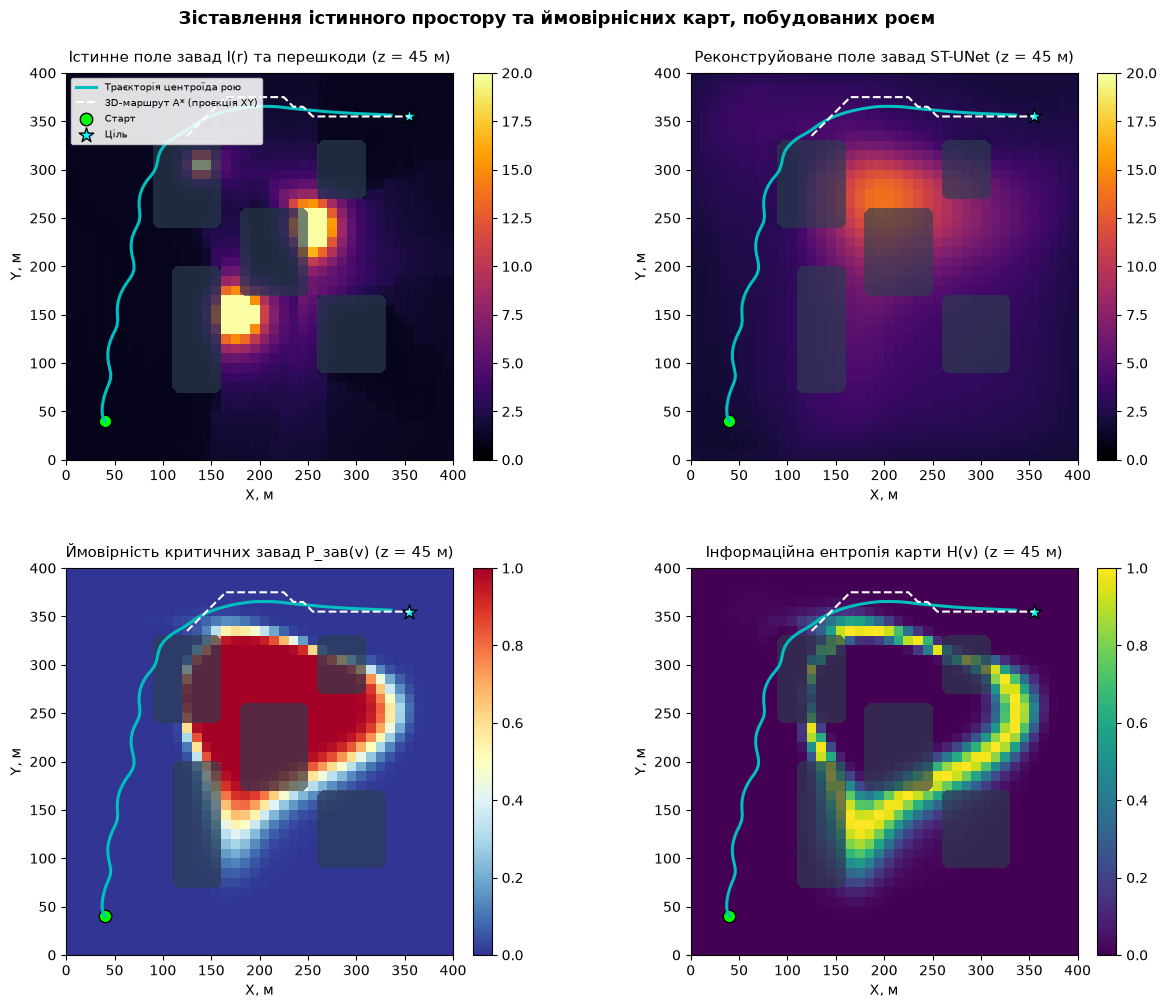

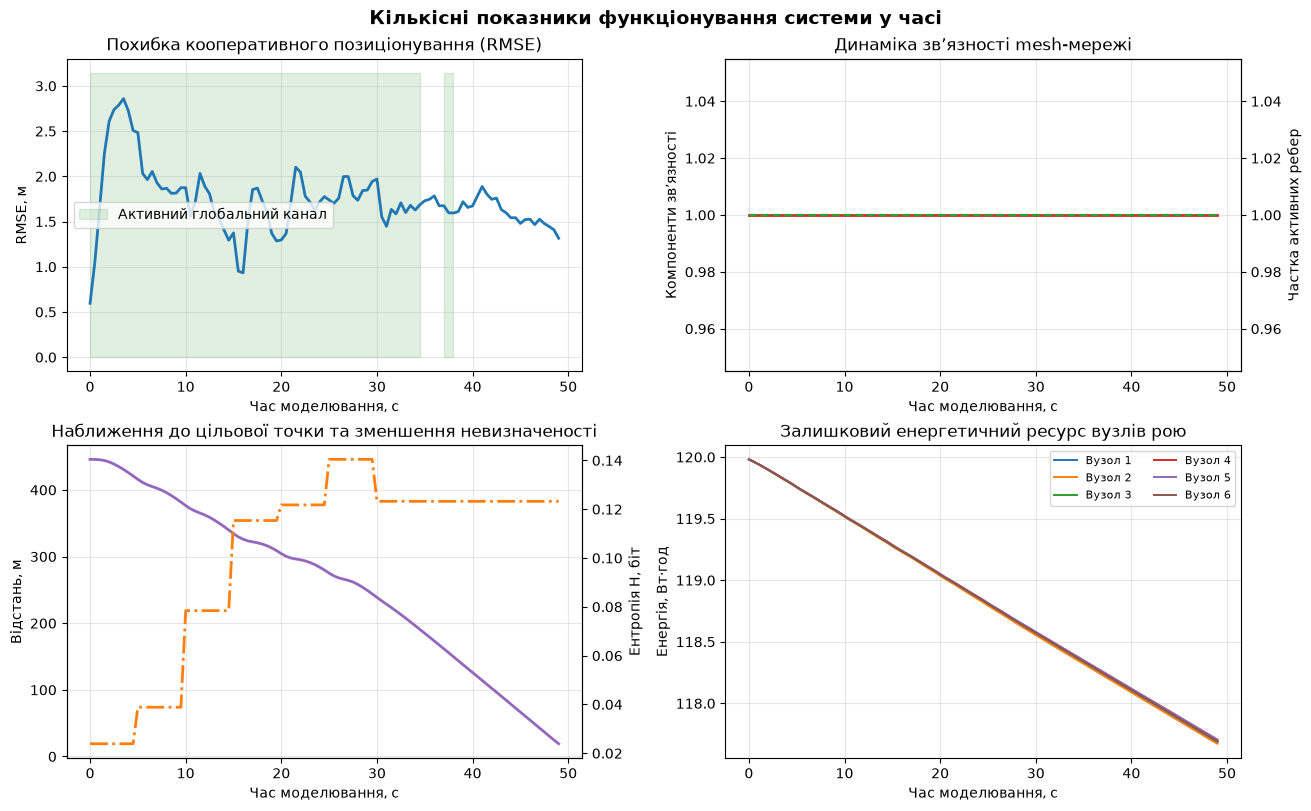

In [8]:
z_slice_idx = int(round(45.0 / CFG.voxel_size))
z_meters = (z_slice_idx + 0.5) * CFG.voxel_size

fig, axes = plt.subplots(2, 2, figsize=(12.5, 10.5))
fig.subplots_adjust(left=0.06, right=0.95, top=0.90, bottom=0.06, wspace=0.28, hspace=0.28)

traj_arr = np.array(hist["pos"])
centroid_traj = traj_arr.mean(axis=1)
last_path = hist["global_path"][-1]

panels = [
    (env.true_jam_grid[:, :, z_slice_idx].T, "Істинне поле завад I(r) та перешкоди", "inferno", 0, 20),
    (sim_res["mean_i"][:, :, z_slice_idx].T, "Реконструйоване поле завад ST-UNet", "inferno", 0, 20),
    (sim_res["p_jam"][:, :, z_slice_idx].T, "Ймовірність критичних завад P_зав(v)", "RdYlBu_r", 0, 1),
    (sim_res["entropy"][:, :, z_slice_idx].T, "Інформаційна ентропія карти H(v)", "viridis", 0, 1),
]

for ax, (data_2d, title, cmap, vmin, vmax) in zip(axes.flat, panels):
    im = ax.imshow(data_2d, origin="lower", extent=[0, CFG.x_max, 0, CFG.y_max], cmap=cmap, vmin=vmin, vmax=vmax, aspect="equal")
    occ_slice = env.occ_grid[:, :, z_slice_idx].T
    ax.contourf(
        np.linspace(5, CFG.x_max - 5, env.nx),
        np.linspace(5, CFG.y_max - 5, env.ny),
        occ_slice,
        levels=[0.5, 1.5],
        colors=["#2c3e50"],
        alpha=0.65,
    )
    ax.plot(centroid_traj[:, 0], centroid_traj[:, 1], "c-", lw=2.2, label="Траєкторія центроїда рою")
    ax.plot(last_path[:, 0], last_path[:, 1], "w--", lw=1.5, label="3D-маршрут A* (проєкція XY)")
    ax.scatter([CFG.start_center[0]], [CFG.start_center[1]], c="lime", s=80, marker="o", edgecolor="k", label="Старт")
    ax.scatter([CFG.goal_point[0]], [CFG.goal_point[1]], c="cyan", s=120, marker="*", edgecolor="k", label="Ціль")
    ax.set_title(f"{title} (z = {z_meters:.0f} м)", fontsize=10.5, pad=8)
    ax.set_xlabel("X, м")
    ax.set_ylabel("Y, м")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

axes[0, 0].legend(loc="upper left", fontsize=7.5, framealpha=0.88)
fig.suptitle("Зіставлення істинного простору та ймовірнісних карт, побудованих роєм", fontsize=13, fontweight="bold", y=0.96)
plt.show()

# Графіки часової динаміки показників ефективності
t_axis = np.arange(len(hist["rmse"])) * CFG.dt
uplink_arr = np.array(hist["uplink"])

fig2, ax2 = plt.subplots(2, 2, figsize=(13, 8), constrained_layout=True)

ax2[0, 0].plot(t_axis, hist["rmse"], color="#1f77b4", lw=2)
ax2[0, 0].fill_between(t_axis, 0, np.max(hist["rmse"]) * 1.1, where=uplink_arr, color="green", alpha=0.12, label="Активний глобальний канал")
ax2[0, 0].set_title("Похибка кооперативного позиціонування (RMSE)")
ax2[0, 0].set_xlabel("Час моделювання, с")
ax2[0, 0].set_ylabel("RMSE, м")
ax2[0, 0].legend()
ax2[0, 0].grid(alpha=0.3)

ax2[0, 1].plot(t_axis, hist["n_components"], color="#d62728", lw=2, label="Кількість компонент графа G[k]")
ax2_twin = ax2[0, 1].twinx()
ax2_twin.plot(t_axis, hist["pdr"], color="#2ca02c", lw=1.6, ls="--", label="Коефіцієнт доставки (PDR)")
ax2[0, 1].set_title("Динаміка зв’язності mesh-мережі")
ax2[0, 1].set_xlabel("Час моделювання, с")
ax2[0, 1].set_ylabel("Компоненти зв’язності")
ax2_twin.set_ylabel("Частка активних ребер")
ax2[0, 1].grid(alpha=0.3)

ax2[1, 0].plot(t_axis, hist["dist_goal"], color="#9467bd", lw=2, label="Відстань до мети")
ax2_e = ax2[1, 0].twinx()
ax2_e.plot(t_axis, hist["mean_entropy"], color="#ff7f0e", lw=2, ls="-.", label="Середня ентропія карти H")
ax2[1, 0].set_title("Наближення до цільової точки та зменшення невизначеності")
ax2[1, 0].set_xlabel("Час моделювання, с")
ax2[1, 0].set_ylabel("Відстань, м")
ax2_e.set_ylabel("Ентропія H, біт")
ax2[1, 0].grid(alpha=0.3)

energy_arr = np.array(hist["energy"])
for i in range(CFG.n_drones):
    ax2[1, 1].plot(t_axis, energy_arr[:, i], lw=1.4, label=f"Вузол {i+1}")
ax2[1, 1].set_title("Залишковий енергетичний ресурс вузлів рою")
ax2[1, 1].set_xlabel("Час моделювання, с")
ax2[1, 1].set_ylabel("Енергія, Вт·год")
ax2[1, 1].legend(ncol=2, fontsize=8)
ax2[1, 1].grid(alpha=0.3)

plt.suptitle("Кількісні показники функціонування системи у часі", fontsize=14, fontweight="bold")
plt.show()

# 8. Інтерактивна тривимірна візуалізація простору, зон завад та анімації руху рою

In [9]:
from IPython.display import HTML, display

def create_box_mesh(box: np.ndarray, name: str, color: str = "slategray", opacity: float = 0.50) -> go.Mesh3d:
    x0, y0, z0, x1, y1, z1 = box
    x = [x0, x1, x1, x0, x0, x1, x1, x0]
    y = [y0, y0, y1, y1, y0, y0, y1, y1]
    z = [z0, z0, z0, z0, z1, z1, z1, z1]
    i = [0, 0, 4, 4, 0, 0, 1, 1, 2, 2, 3, 3]
    j = [1, 2, 5, 6, 1, 5, 2, 6, 3, 7, 0, 4]
    k = [2, 3, 6, 7, 5, 4, 6, 5, 7, 6, 4, 7]
    return go.Mesh3d(x=x, y=y, z=z, i=i, j=j, k=k, color=color, opacity=opacity, name=name, showlegend=False)


def build_interactive_3d_scene(env: Environment3D, sim_res: Dict, cfg: SimConfig, frame_stride: int = 4):
    hist = sim_res["history"]
    traj = np.array(hist["pos"])
    adjs = hist["adj"]
    t_len = traj.shape[0]

    static_traces = []
    for idx_b, box in enumerate(env.obstacles):
        static_traces.append(create_box_mesh(box, name=f"Перешкода {idx_b+1}"))

    gx, gy, gz = env.grid_x.flatten(), env.grid_y.flatten(), env.grid_z.flatten()
    p_flat = sim_res["p_jam"].flatten()
    static_traces.append(
        go.Isosurface(
            x=gx, y=gy, z=gz, value=p_flat,
            isomin=0.50, isomax=0.95, surface_count=2,
            opacity=0.30, colorscale="Reds",
            caps=dict(x_show=False, y_show=False, z_show=False),
            name="Зона завад (P >= 0.50)",
            showscale=True,
            colorbar=dict(title="P_зав", x=1.02, len=0.72, y=0.45),
        )
    )

    jam_pts = np.array([jm["pos"] for jm in env.jammers])
    static_traces.append(
        go.Scatter3d(
            x=jam_pts[:, 0], y=jam_pts[:, 1], z=jam_pts[:, 2],
            mode="markers", marker=dict(size=7, color="red", symbol="diamond"),
            name="Джерела завад",
        )
    )
    static_traces.append(
        go.Scatter3d(
            x=[cfg.start_center[0], cfg.goal_point[0]],
            y=[cfg.start_center[1], cfg.goal_point[1]],
            z=[cfg.start_center[2], cfg.goal_point[2]],
            mode="markers+text", text=["Старт", "Ціль"], textposition="top center",
            marker=dict(size=8, color=["lime", "cyan"]), name="Старт і ціль",
        )
    )

    for i in range(cfg.n_drones):
        static_traces.append(
            go.Scatter3d(
                x=traj[:, i, 0], y=traj[:, i, 1], z=traj[:, i, 2],
                mode="lines", line=dict(width=3, color="royalblue"),
                opacity=0.65, name="Траєкторії дронів", showlegend=(i == 0),
            )
        )

    def get_dynamic_traces(step_idx: int):
        cur_p = traj[step_idx]
        cur_adj = adjs[step_idx]
        ex, ey, ez = [], [], []
        for a in range(cfg.n_drones):
            for b in range(a + 1, cfg.n_drones):
                if cur_adj[a, b] > 0:
                    ex += [cur_p[a, 0], cur_p[b, 0], None]
                    ey += [cur_p[a, 1], cur_p[b, 1], None]
                    ez += [cur_p[a, 2], cur_p[b, 2], None]
        return [
            go.Scatter3d(
                x=cur_p[:, 0], y=cur_p[:, 1], z=cur_p[:, 2],
                mode="markers+text", text=[f"D{i+1}" for i in range(cfg.n_drones)],
                marker=dict(size=6, color="gold", line=dict(width=1, color="black")),
                name="Позиції дронів",
            ),
            go.Scatter3d(
                x=ex, y=ey, z=ez,
                mode="lines", line=dict(width=3, color="limegreen"),
                name="Канали mesh-мережі",
            ),
        ]

    init_dyn = get_dynamic_traces(0)
    n_static = len(static_traces)

    frames = []
    frame_indices = list(range(0, t_len, frame_stride))
    if frame_indices[-1] != t_len - 1:
        frame_indices.append(t_len - 1)

    for k_idx in frame_indices:
        frames.append(
            go.Frame(
                data=get_dynamic_traces(k_idx),
                traces=[n_static, n_static + 1],
                name=str(k_idx),
                layout=go.Layout(
                    title_text=(
                        f"3D-модель рою | k={k_idx} (t={k_idx*cfg.dt:.1f} с) | "
                        f"Канал: {'ОНЛАЙН' if hist['uplink'][k_idx] else 'АВТОНОМНО'}"
                    )
                ),
            )
        )

    fig3d = go.Figure(data=static_traces + init_dyn, frames=frames)
    fig3d.update_layout(
        title=dict(text="3D-модель навігації рою та прогнозованого поля завад", font=dict(size=15), x=0.5),
        height=760,
        margin=dict(l=10, r=80, t=65, b=20),
        legend=dict(
            x=0.01, y=0.96, xanchor="left", yanchor="top",
            bgcolor="rgba(255, 255, 255, 0.85)", bordercolor="lightgray", borderwidth=1, font=dict(size=11)
        ),
        scene=dict(
            xaxis=dict(title="X, м", range=[0, cfg.x_max]),
            yaxis=dict(title="Y, м", range=[0, cfg.y_max]),
            zaxis=dict(title="Z, м", range=[0, cfg.z_max]),
            aspectmode="manual", aspectratio=dict(x=1.0, y=1.0, z=0.35),
        ),
        updatemenus=[
            dict(
                type="buttons", showactive=False, y=0.04, x=0.02,
                buttons=[
                    dict(label="Відтворити", method="animate", args=[None, {"frame": {"duration": 110, "redraw": True}, "fromcurrent": True}]),
                    dict(label="Пауза", method="animate", args=[[None], {"frame": {"duration": 0, "redraw": False}, "mode": "immediate"}]),
                ],
            )
        ],
        sliders=[
            dict(
                steps=[dict(method="animate", args=[[f.name], {"mode": "immediate", "frame": {"duration": 0, "redraw": True}}], label=f"{int(f.name)*cfg.dt:.0f}с") for f in frames],
                x=0.18, len=0.76, y=0.04, currentvalue={"prefix": "Час: "},
            )
        ],
    )
    fig3d.write_html("swarm_3d_simulation.html")
    display(HTML(fig3d.to_html(include_plotlyjs="cdn", full_html=False)))


build_interactive_3d_scene(env, sim_res, CFG, frame_stride=4)